In [5]:
#Import TensorFlow and other necessary libraries
import matplotlib.pyplot as plt
import numpy as np
import PIL
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential ,Model
from tensorflow.keras.layers import Dense, Dropout, Flatten,Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import BatchNormalization
from tensorflow.keras.layers import LeakyReLU

In [6]:
#dataset
import pathlib

dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir = tf.keras.utils.get_file('flower_photos.tar', origin=dataset_url, extract=True)
data_dir = pathlib.Path(data_dir).with_suffix('')

In [7]:
# Count the number of images in the dataset and display the count
image_count = len(list(data_dir.glob('*/*.jpg')))
print(image_count)

3670


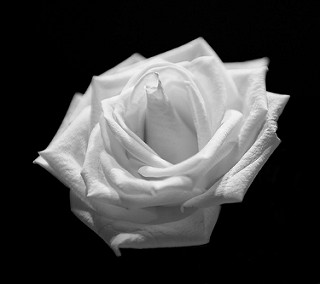

In [8]:
# Display an example image from the 'roses' category
roses = list(data_dir.glob('roses/*'))
PIL.Image.open(str(roses[0]))

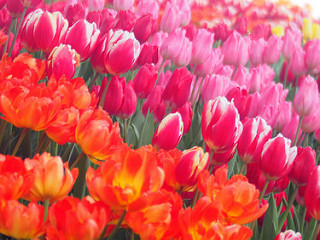

In [9]:
tulips = list(data_dir.glob('tulips/*'))
PIL.Image.open(str(tulips[0]))

In [10]:
# Define batch size and image dimensions
batch_size = 32
img_height = 180
img_width = 180

In [11]:
# Create training datasets using image_dataset_from_directory
train_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.


In [12]:
# Create validation datasets using image_dataset_from_directory
val_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 3670 files belonging to 5 classes.
Using 734 files for validation.


In [13]:
#Get class names from the training dataset and display them
class_names = train_ds.class_names
print(class_names)

['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


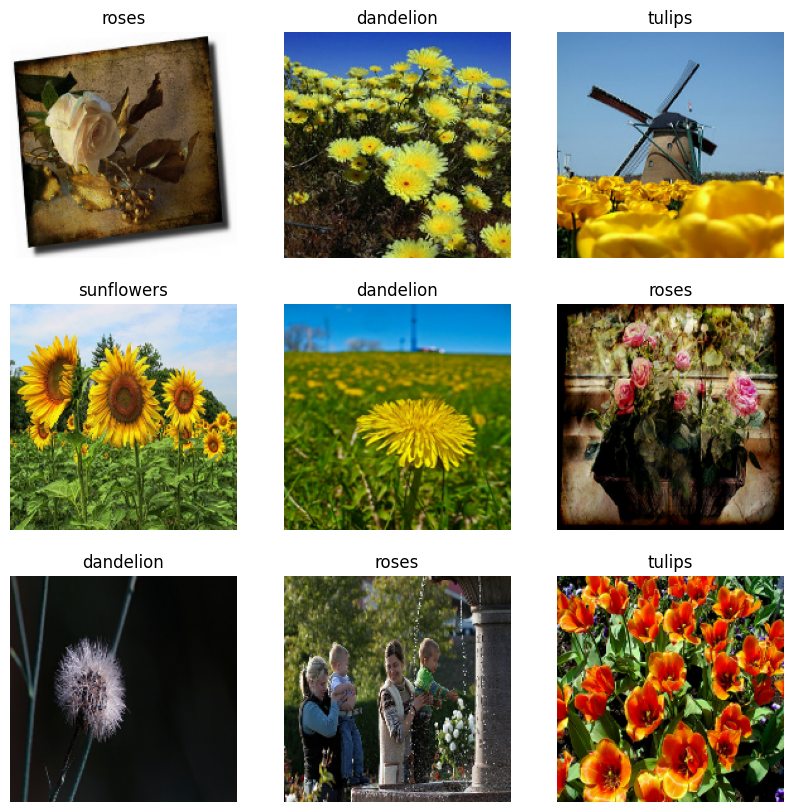

In [14]:
# Visualize a batch of images from the training dataset
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")

In [15]:
for image_batch, labels_batch in train_ds:
  print(image_batch.shape)
  print(labels_batch.shape)
  break

(32, 180, 180, 3)
(32,)


In [16]:
#Cache, shuffle, and prefetch the training and validation datasets for better performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [17]:
# Normalize pixel values in the datasets to [0, 1]
normalization_layer = layers.Rescaling(1./255)

In [19]:
normalized_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
image_batch, labels_batch = next(iter(normalized_ds))
first_image = image_batch[0]
# Notice the pixel values are now in `[0,1]`.
print(np.min(first_image), np.max(first_image))

0.0 1.0


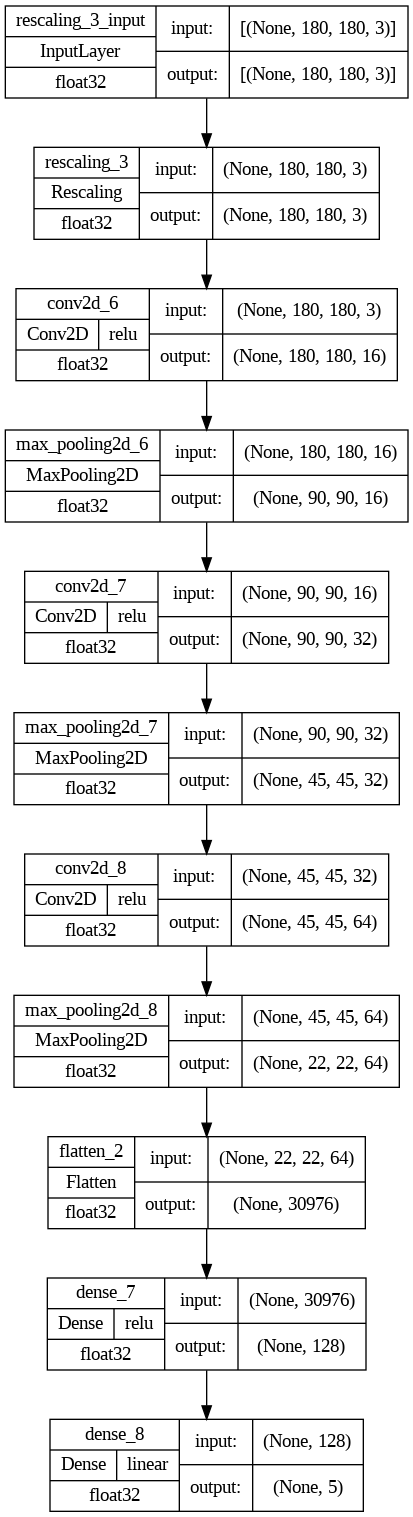

In [27]:
#Define the number of classes based on the class names
num_classes = len(class_names)

# Define the convolutional neural network (CNN) model architecture
model = Sequential([
  layers.Rescaling(1./255, input_shape=(img_height, img_width, 3)),
  layers.Conv2D(16, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Flatten(),
  layers.Dense(128, activation='relu'),
  layers.Dense(num_classes)
])
# Import the necessary function to plot the model
from tensorflow.keras.utils import plot_model

# Plot the model with additional information
plot_model(
    model,
    show_shapes=True,
    show_dtype=True,
    show_layer_activations=True
)

In [28]:
# Compile the model with appropriate optimizer, loss function, and metrics
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [29]:
model.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling_3 (Rescaling)     (None, 180, 180, 3)       0         
                                                                 
 conv2d_6 (Conv2D)           (None, 180, 180, 16)      448       
                                                                 
 max_pooling2d_6 (MaxPoolin  (None, 90, 90, 16)        0         
 g2D)                                                            
                                                                 
 conv2d_7 (Conv2D)           (None, 90, 90, 32)        4640      
                                                                 
 max_pooling2d_7 (MaxPoolin  (None, 45, 45, 32)        0         
 g2D)                                                            
                                                                 
 conv2d_8 (Conv2D)           (None, 45, 45, 64)       

In [30]:
#Training our convolutional neural network model
epochs=10
history = model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=epochs
)

Epoch 1/10
92/92 [==============================] - 106s 1s/step - loss: 1.3441 - accuracy: 0.4435 - val_loss: 1.1156 - val_accuracy: 0.5545
Epoch 2/10
92/92 [==============================] - 96s 1s/step - loss: 1.0100 - accuracy: 0.6012 - val_loss: 1.0269 - val_accuracy: 0.6090
Epoch 3/10
92/92 [==============================] - 96s 1s/step - loss: 0.8403 - accuracy: 0.6866 - val_loss: 0.9287 - val_accuracy: 0.6362
Epoch 4/10
92/92 [==============================] - 101s 1s/step - loss: 0.6572 - accuracy: 0.7548 - val_loss: 1.0382 - val_accuracy: 0.6144
Epoch 5/10
92/92 [==============================] - 99s 1s/step - loss: 0.4707 - accuracy: 0.8392 - val_loss: 1.0927 - val_accuracy: 0.6253
Epoch 6/10
92/92 [==============================] - 102s 1s/step - loss: 0.2779 - accuracy: 0.9070 - val_loss: 1.2815 - val_accuracy: 0.6144
Epoch 7/10
92/92 [==============================] - 100s 1s/step - loss: 0.1708 - accuracy: 0.9441 - val_loss: 1.4614 - val_accuracy: 0.6294
Epoch 8/10
92/92

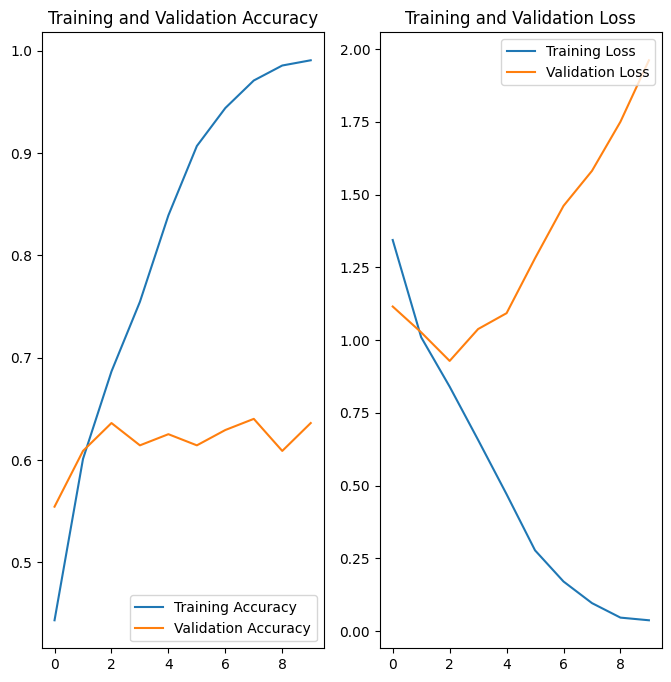

In [31]:
# Retrieve training and validation metrics for visualization
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(epochs)

# Visualize training and validation accuracy and loss
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

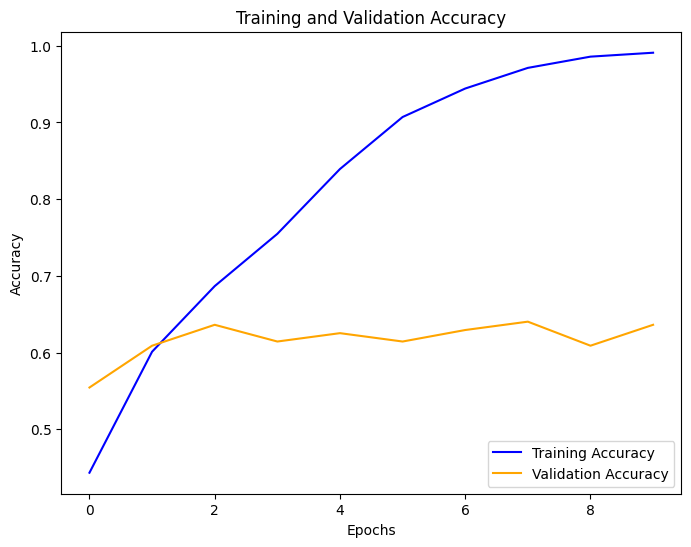

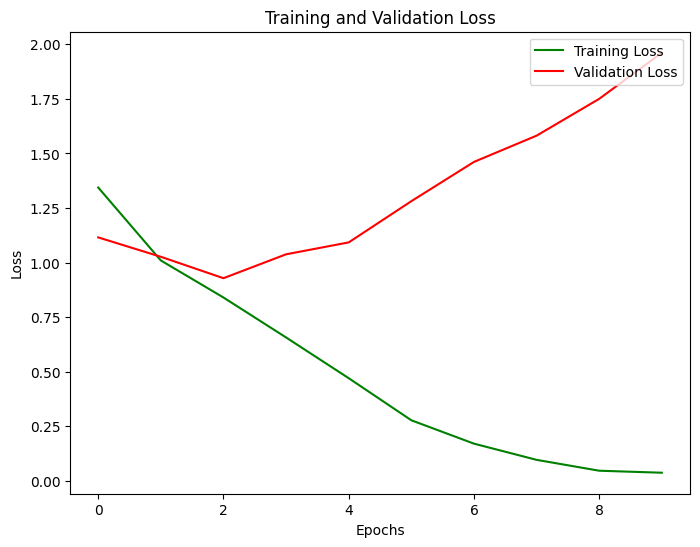

In [32]:

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(epochs)

# Plotting Training and Validation Accuracy in a separate figure with different colors
plt.figure(figsize=(8, 6))
plt.plot(epochs_range, acc, label='Training Accuracy', color='blue')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='orange')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

# Plotting Training and Validation Loss in a separate figure with different colors
plt.figure(figsize=(8, 6))
plt.plot(epochs_range, loss, label='Training Loss', color='green')
plt.plot(epochs_range, val_loss, label='Validation Loss', color='red')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

In [33]:
# Make predictions on test data
test_X = []
test_Y = []
for images, labels in val_ds:
    test_X.extend(images.numpy())
    test_Y.extend(labels.numpy())

test_X = np.array(test_X)
test_Y = np.array(test_Y)

predicted_classes = model.predict(test_X)
predicted_classes = np.argmax(np.round(predicted_classes), axis=1)

23/23 [==============================] - 12s 510ms/step


(734,) (734,)
Found 258 incorrectly classified labels


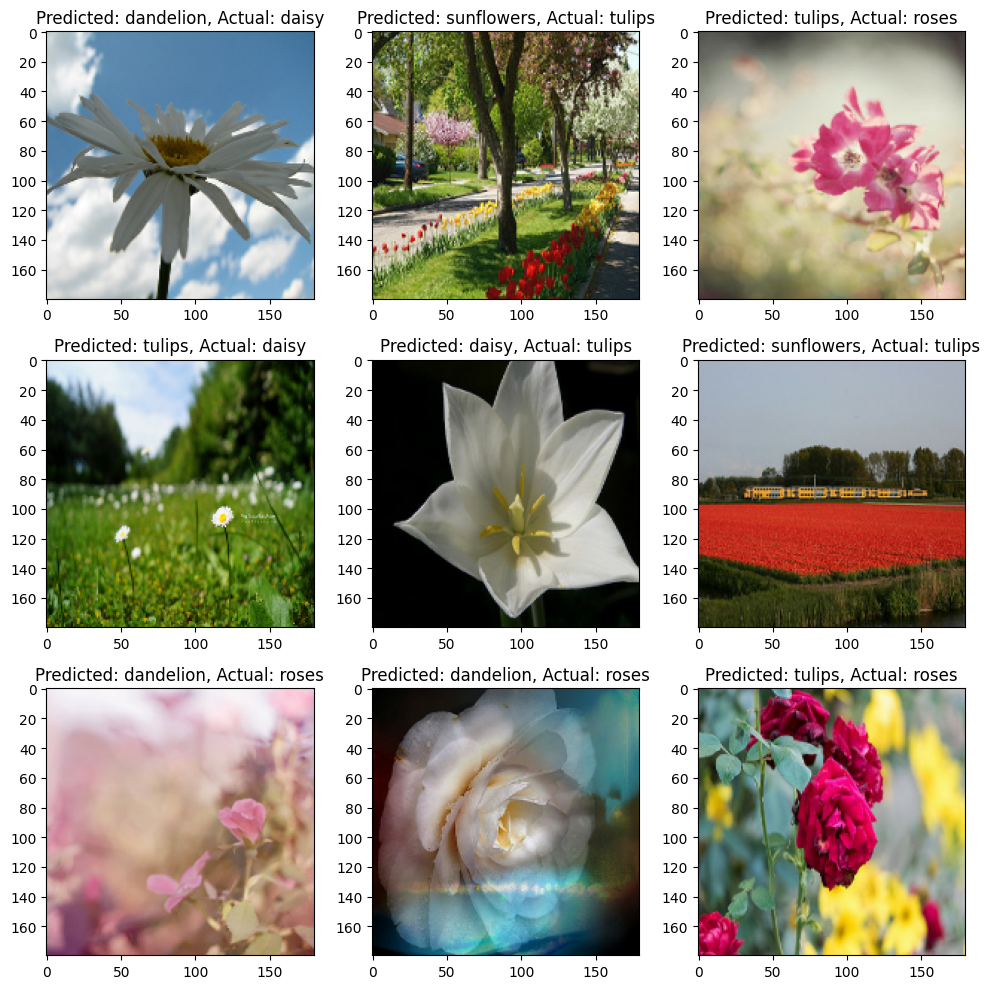

In [34]:
# Check shapes
print(predicted_classes.shape, test_Y.shape)

# Find incorrectly classified images
incorrect = np.where(predicted_classes != test_Y)[0]
print("Found %d incorrectly classified labels" % len(incorrect))

# Plot the first 9 incorrectly classified images
plt.figure(figsize=(10, 10))
for i, idx in enumerate(incorrect[:9]):
    plt.subplot(3, 3, i + 1)
    plt.imshow(test_X[idx].reshape(180, 180, 3).astype(np.uint8))
    plt.title("Predicted: {}, Actual: {}".format(class_names[predicted_classes[idx]], class_names[test_Y[idx]]))
    plt.tight_layout()

plt.show()